<a href="https://colab.research.google.com/github/Sands225/Poultry-Disease-Classification/blob/YOLOv8/%5BBaseline_YOLOv8%5D_Poultry_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Poultry Disease Classification
Baseline Model YOLOv8

## Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Library Import & Configuration

In [ ]:
import os, re, shutil, random, hashlib, inspect, subprocess, sys
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

try:
    import albumentations as A
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'albumentations'])
    import albumentations as A
print('albumentations', A.__version__)

albumentations 2.0.8


In [ ]:
SEED        = 42
EXTS        = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
NEAR_THRESH = 4            # jarak hamming dHash untuk "gambar mirip"
NEAR_MODE   = 'group'      # 'group' = near-dup disatukan di split yang sama | 'drop' = near-dup dibuang (sisakan 1)
SPLIT       = (0.70, 0.15, 0.15)   # train / val / test
EXP_NAME    = 'YOLOv8_baseline'    # nama eksperimen (dipakai untuk folder dataset & run training)
TARGET_PER_CLASS = 1600    # target jumlah gambar TRAIN per kelas | None = tanpa balancing (baseline)

# ---- Lokasi input (Drive) ----
DRIVE_IN   = '/content/drive/MyDrive/College/Deep Learning/Tugas 2/'
DRIVE_DS   = f'{DRIVE_IN}augmented_dataset_v1'      # sumber (Drive, hanya dibaca)
LOCAL_DS   = '/content/augmented_dataset_v1'        # salinan lokal (dipakai training)
IMG_ROOT   = f'{DRIVE_IN}/images'
LABEL_ROOT = f'{DRIVE_IN}/labels'

DATA_YAML  = '/content/data.yaml'                   # yaml lokal

# ---- Lokasi output ----
# OUT        = f'/content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8'
DATA_YAML  = f'/content/data.yaml'
DRIVE_OUT  = f'/content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8'
DRIVE_EXP  = f'{DRIVE_OUT}/{EXP_NAME}'
DRIVE_RUNS = f'{DRIVE_EXP}/runs'
LAPORAN    = f'{DRIVE_EXP}/laporan'
MODEL_NAME = 'yolov8n.pt'                              # 'yolo11n.pt' atau 'yolov8n.pt'
TAG        = os.path.splitext(MODEL_NAME)[0]           # 'yolov8n'
RUN_NAME   = f'{EXP_NAME}_{TAG}'                       # 'ros1600_yolov8n'
RUN        = f'{DRIVE_RUNS}/{RUN_NAME}'
os.makedirs(LAPORAN, exist_ok=True); os.makedirs(DRIVE_RUNS, exist_ok=True)
print("Output permanen →", DRIVE_EXP)

random.seed(SEED); np.random.seed(SEED)

Output permanen → /content/drive/MyDrive/College/Deep Learning/Tugas 2/output_YOLOv8/YOLOv8_baseline


In [ ]:
from concurrent.futures import ThreadPoolExecutor

# --- 1. Salin dataset Drive -> lokal (sekali per sesi, paralel biar cepat) ---
if not os.path.exists(f'{LOCAL_DS}/images/test'):
    files = [os.path.join(r, f) for r, _, fs in os.walk(DRIVE_DS)
             for f in fs if not f.endswith('.cache') and f != 'data.yaml']

    def salin(src):
        dst = os.path.join(LOCAL_DS, os.path.relpath(src, DRIVE_DS))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copyfile(src, dst)

    with ThreadPoolExecutor(16) as ex:
        list(tqdm(ex.map(salin, files), total=len(files), desc='Salin ke lokal'))
else:
    print('Dataset lokal sudah ada, lewati penyalinan.')

# --- 2. Buat data.yaml LOKAL (yaml di Drive tidak disentuh) ---
KELAS = ['cocci', 'healthy', 'ncd', 'salmo']
yaml_text = (f"path: {LOCAL_DS}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
             + ''.join(f"  {i}: {k}\n" for i, k in enumerate(KELAS)))
with open(DATA_YAML, 'w') as f:
    f.write(yaml_text)
print(yaml_text)

# --- 3. Cek jumlah file ---
for s in ['train', 'val', 'test']:
    print(s, '| gambar:', len(os.listdir(f'{LOCAL_DS}/images/{s}')),
             '| label:',  len(os.listdir(f'{LOCAL_DS}/labels/{s}')))

Salin ke lokal:   0%|          | 0/17661 [00:00<?, ?it/s]

path: /content/augmented_dataset_v1
train: images/train
val: images/val
test: images/test
names:
  0: cocci
  1: healthy
  2: ncd
  3: salmo

train | gambar: 6400 | label: 6400
val | gambar: 1946 | label: 973
test | gambar: 971 | label: 971


In [ ]:
assert os.path.exists(f'{LOCAL_DS}/images/test') and os.path.exists(DATA_YAML), \
    "Dataset lokal belum ada (runtime mungkin reset). Jalankan ulang sel 7."
print("Dataset lokal siap:", LOCAL_DS)

Dataset lokal siap: /content/augmented_dataset_v1


In [ ]:
os.environ['WANDB_DISABLED'] = 'true'
try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    from ultralytics import YOLO

model = YOLO(MODEL_NAME)
results = model.train(
    data=DATA_YAML, epochs=50, imgsz=640, batch=16, patience=15,
    seed=SEED, workers=4, cache='disk', plots=True,
    project=DRIVE_RUNS, name=RUN_NAME, exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

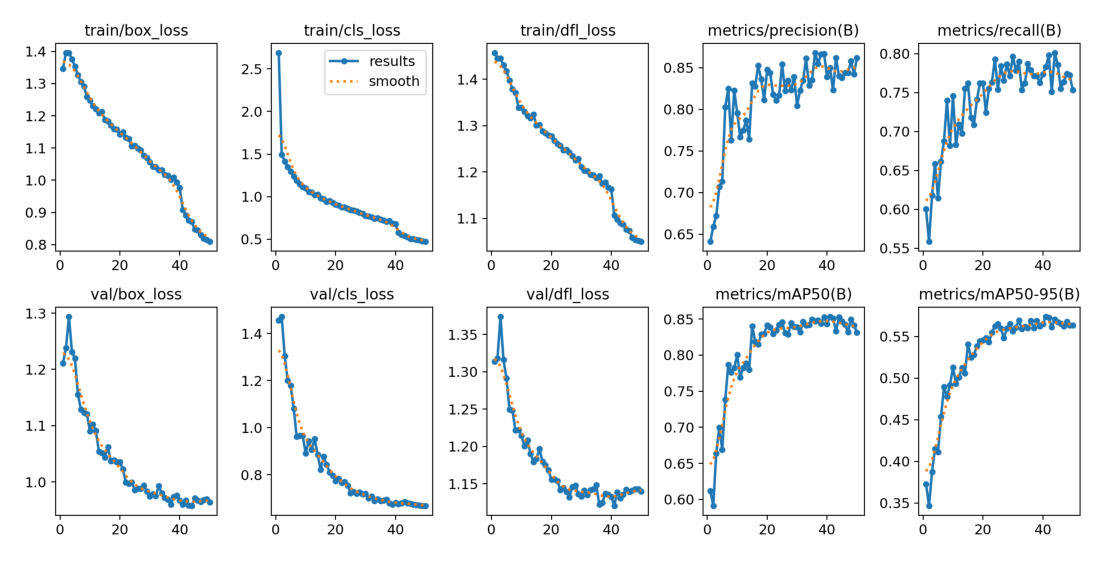

In [ ]:
plt.figure(figsize=(14, 8))
plt.imshow(Image.open(f'{RUN}/results.png')); plt.axis('off'); plt.show()

In [ ]:
best = YOLO(f'{RUN}/weights/best.pt')
m = best.val(data=DATA_YAML, split='test', project=DRIVE_RUNS, name=f'{RUN_NAME}_test', exist_ok=True)

print(f"\nmAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f} | P: {m.box.mp:.3f} | R: {m.box.mr:.3f}")
rows = []
for i, ci in enumerate(m.box.ap_class_index):
    p, r_, ap50, ap = m.box.class_result(i)
    rows.append((m.names[int(ci)], p, r_, ap50, ap))
display(pd.DataFrame(rows, columns=['kelas', 'precision', 'recall', 'mAP50', 'mAP50-95']).set_index('kelas').round(3))

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 188.8±43.1 MB/s, size: 1550.4 KB)
val: Scanning /content/augmented_dataset_v1/labels/test... 971 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 971/971 286.5it/s 3.4s
val: New cache created: /content/augmented_dataset_v1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 1.6it/s 38.3s
                   all        971       1295       0.86      0.737       0.83      0.559
                 cocci        294        416      0.904      0.733      0.839      0.658
               healthy        307        500      0.888       0.75      0.877      0.698
                   ncd         56         57      0.767      0.636      0.703      0.318
                 salmo        314        322      0.881   

,precision,recall,mAP50,mAP50-95
kelas,,,,
cocci,0.904,0.733,0.839,0.658
healthy,0.888,0.750,0.877,0.698
ncd,0.767,0.636,0.703,0.318
salmo,0.881,0.829,0.902,0.563


In [ ]:
CSV_HASIL = f'{DRIVE_OUT}/hasil_eksperimen.csv'
baris = [(RUN_NAME, 'ALL', m.box.mp, m.box.mr, m.box.map50, m.box.map)]
for i, ci in enumerate(m.box.ap_class_index):
    p, r_, ap50, ap = m.box.class_result(i)
    baris.append((RUN_NAME, m.names[int(ci)], p, r_, ap50, ap))
baru = pd.DataFrame(baris, columns=['exp', 'kelas', 'precision', 'recall', 'mAP50', 'mAP50-95'])
if os.path.exists(CSV_HASIL):
    lama = pd.read_csv(CSV_HASIL)
    baru = pd.concat([lama[lama.exp != RUN_NAME], baru], ignore_index=True)
baru.to_csv(CSV_HASIL, index=False)
for metrik in ['recall', 'mAP50-95']:
    print(f"\n{metrik} per kelas, per eksperimen:")
    display(baru.pivot(index='kelas', columns='exp', values=metrik).round(3))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, fn in zip(ax, ['confusion_matrix.png', 'confusion_matrix_normalized.png']):
    a.imshow(Image.open(f'{m.save_dir}/{fn}')); a.axis('off')
plt.tight_layout(); plt.show()

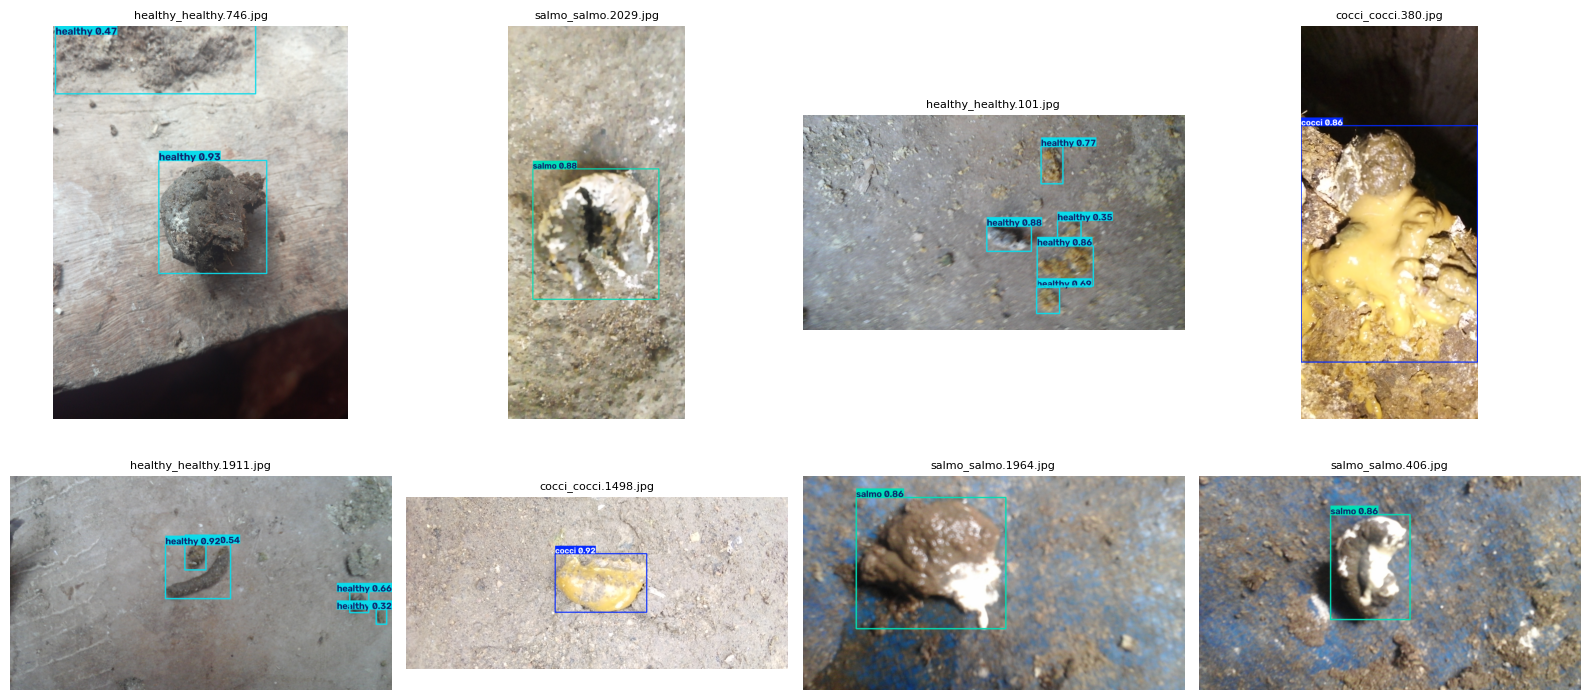

In [ ]:
test_imgs = [f'{LOCAL_DS}/images/test/{f}' for f in os.listdir(f'{LOCAL_DS}/images/test')]
sampel = random.sample(test_imgs, min(8, len(test_imgs)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axes.flat, sampel):
    r_ = best.predict(p, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r_.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(p), fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()